In [3]:
"""
import pandas as pd

#For creating the test and train/pool datasets from the original excel file

excel_file = pd.read_excel("../real_data/original_table.xlsx")
excel_file["YES/NO"] = excel_file["YES/NO"].astype("string").str.strip()

test = excel_file[excel_file["test/train/pool"]== "test"]
test = test.drop(columns=[
    "Lana",
    "Denis",
    "test/train/pool",
    "Note",
    "Genus classification",
    "Found in multiple samples",
    "Protein",
    "Read count for this sample",
    "mmseq cov and id",
    "length2",
    "blast hits",
    "genome organization",
    "Virus movement protein in theory?",
    "group"
])
test.to_csv("test.tsv", sep="\t", index=False)

train_pool = excel_file[excel_file["test/train/pool"]!= "test"]
train_pool = train_pool.drop(columns=[
    "Lana",
    "Denis",
    "test/train/pool",
    "Note",
    "Genus classification",
    "Found in multiple samples",
    "Protein",
    "Read count for this sample",
    "mmseq cov and id",
    "length2",
    "blast hits",
    "genome organization",
    "Virus movement protein in theory?",
    "group"
])
#train_pool.to_csv("train_pool.tsv", sep="\t", index=False)
"""

In [2]:
import os
import re
import glob
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def feature_importance_all(num_iterations, name,
                           input_dir="feature_importance"):

    all_df = []

    for iteration in range(num_iterations):
        df = pd.read_csv(
            os.path.join(input_dir,
                         f"{name}_feature_importance_iter_{iteration}.csv")
        )
        df["iteration"] = iteration
        all_df.append(df)

    importance = pd.concat(all_df, ignore_index=True)

    # Enaka razvrstitev kot prej - po povprečni importance
    pivot = importance.pivot(
        index="feature",
        columns="iteration",
        values="importance_mean"
    )

    pivot["mean"] = pivot.mean(axis=1)
    pivot = pivot.sort_values("mean", ascending=False).drop(columns="mean")

    n_iter = len(pivot.columns)
    bar_height = 0.8 / n_iter

    y = np.arange(len(pivot))

    plt.figure(figsize=(10,8))

    for i, iteration in enumerate(pivot.columns):
        plt.barh(
            y + i * bar_height,
            pivot[iteration],
            height=bar_height,
            label=f"Iteration {iteration}"
        )

    plt.yticks(
        y + (n_iter - 1) * bar_height / 2,
        pivot.index
    )

    plt.xlabel("Permutation importance based on F1")
    plt.title(f"Feature importance across all iterations for {name} set")
    plt.legend(title="Iteration")
    plt.tight_layout()
    plt.show()


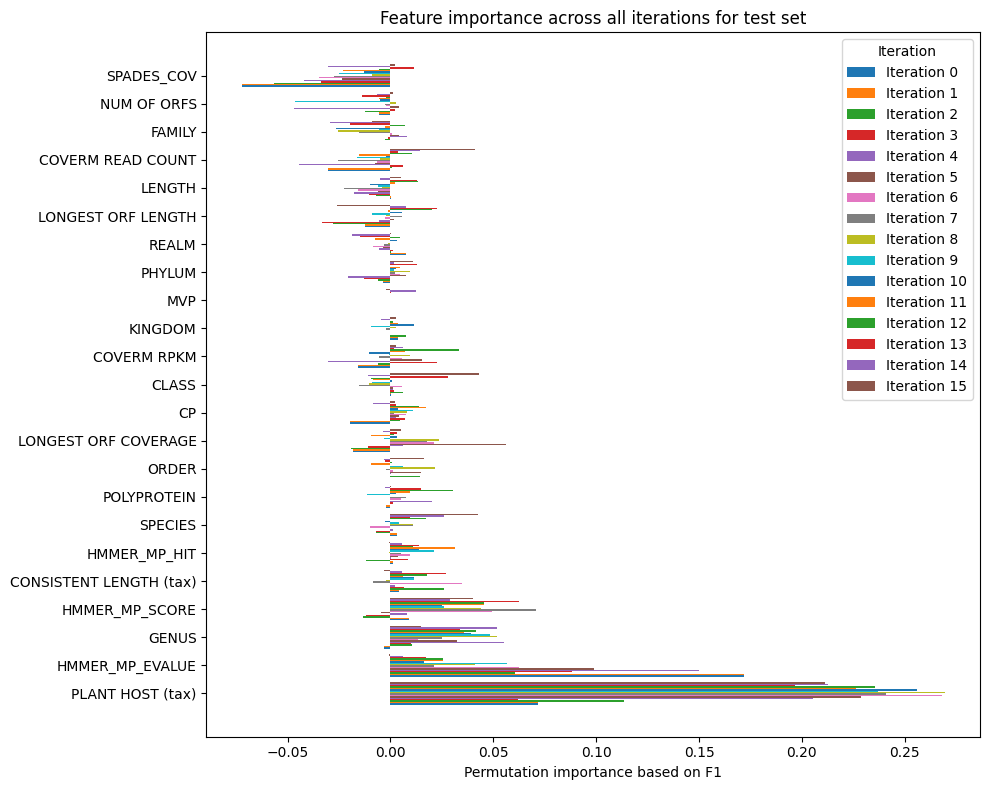

In [4]:
feature_importance_all(num_iterations=16, name="test")

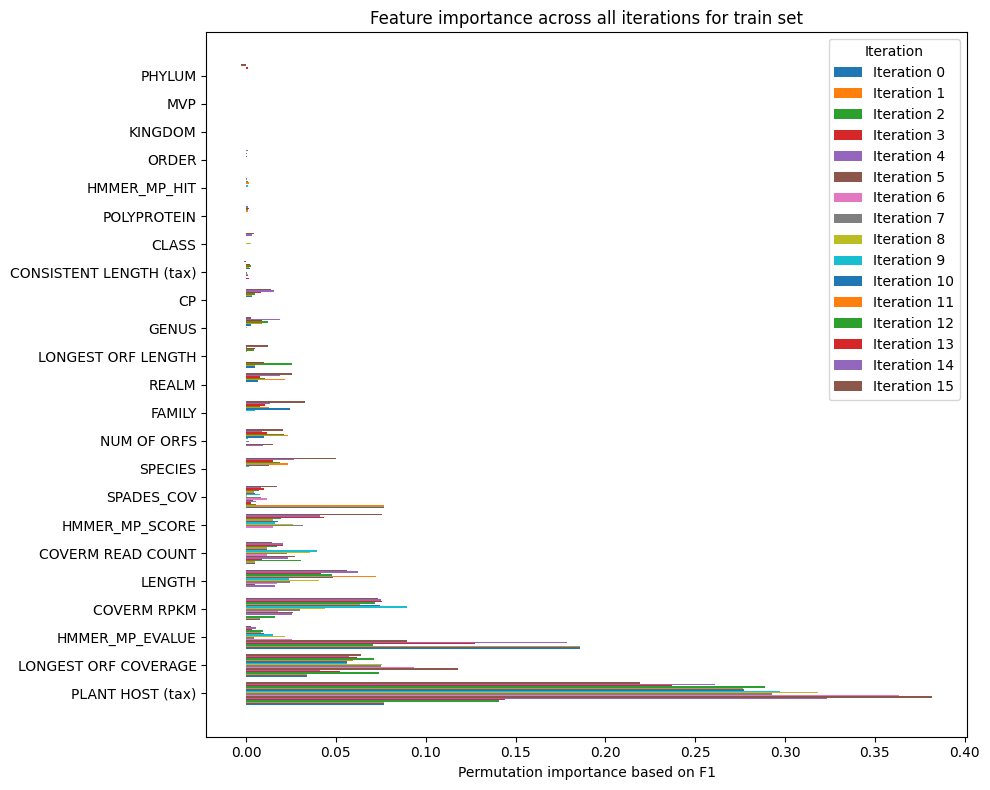

In [5]:
feature_importance_all(num_iterations=16, name="train")

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import os

def probability_distribution_all(num_iterations,
                                 dataset="test",
                                 input_dir="predictions"):

    plt.figure(figsize=(8,6))

    for iteration in range(num_iterations):

        df = pd.read_csv(
            os.path.join(
                input_dir,
                f"{dataset}_predictions_iter_{iteration}.csv"
            )
        )

        plt.hist(
            df["prob_Yes"],
            bins=20,
            range=(0,1),
            alpha=0.4,
            label=f"Iteration {iteration}"
        )

    plt.xlabel("Probability of Yes")
    plt.ylabel("Number of viruses/contigs")
    plt.title(f"{dataset.capitalize()} probability distribution")
    plt.xlim(0,1)
    plt.legend()
    plt.tight_layout()
    plt.show()

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import os

def probability_distribution_all(num_iterations,
                                 dataset="test",
                                 input_dir="predictions"):

    all_probs = []

    for iteration in range(num_iterations):
        df = pd.read_csv(
            os.path.join(
                input_dir,
                f"{dataset}_predictions_iter_{iteration}.csv"
            )
        )
        all_probs.append(df["prob_Yes"])

    plt.figure(figsize=(8,6))

    plt.hist(
        all_probs,
        bins=20,
        range=(0,1),
        label=[f"Iteration {i}" for i in range(num_iterations)],
        histtype="bar"   # privzeto
    )

    plt.xlabel("Probability of Yes")
    plt.ylabel("Number of viruses/contigs")
    plt.title(f"{dataset.capitalize()} probability distribution")
    plt.xlim(0,1)
    plt.legend()
    plt.tight_layout()
    plt.show()

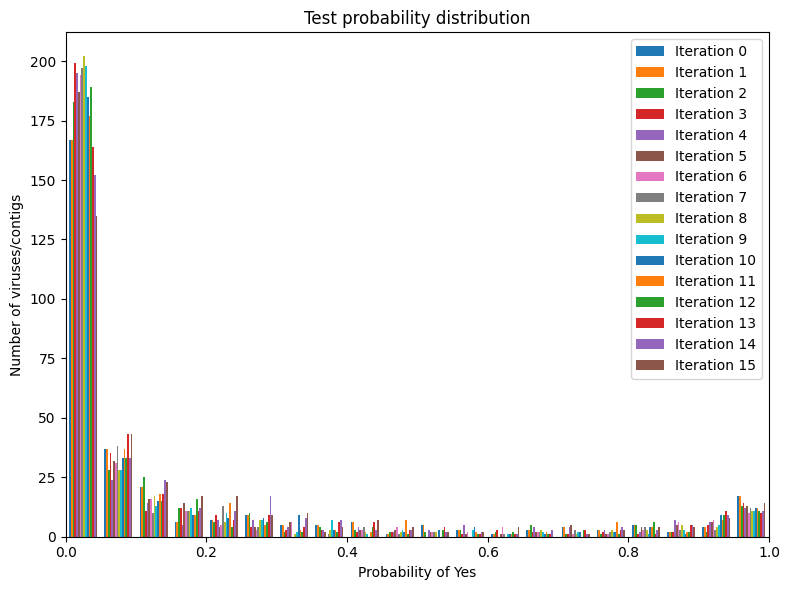

In [8]:
probability_distribution_all(num_iterations=16, dataset="test")

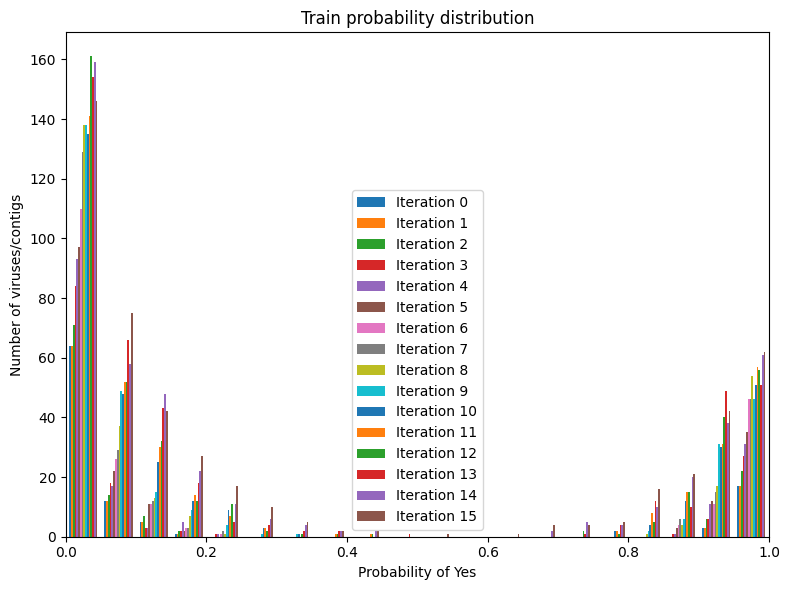

In [10]:
probability_distribution_all(num_iterations=16, dataset="train")

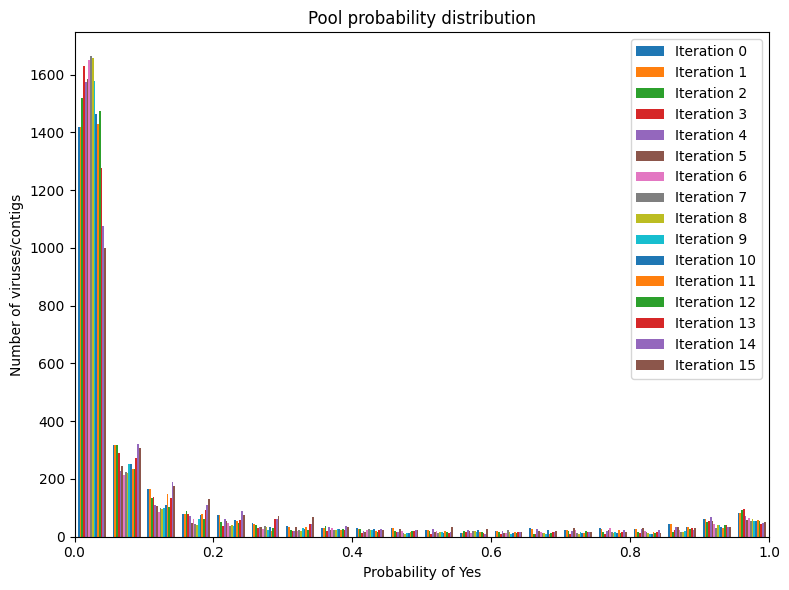

In [11]:
probability_distribution_all(num_iterations=16, dataset="pool")

In [12]:
from sklearn.impute import SimpleImputer

# samo numerične značilke
X_numeric = X.select_dtypes(include=np.number)

# zamenjaj NaN z mediano stolpca
imputer = SimpleImputer(strategy="median")

X_numeric_imputed = imputer.fit_transform(X_numeric)

print(np.isnan(X_numeric_imputed).sum())  # mora biti 0


# KMeans
kmeans = KMeans(
    n_clusters=2,
    random_state=42
)

kmeans.fit(X_numeric_imputed)


# najbližje točke centroidom
closest_indices, distances = pairwise_distances_argmin_min(
    kmeans.cluster_centers_,
    X_numeric_imputed
)


# ID-ji originalnih primerov
centers = X.index[closest_indices]

print(centers)


NameError: name 'X' is not defined

In [13]:
import pandas as pd
import numpy as np

# poti do datotek
file_iter4 = "train_pool_iter4.tsv"
file_iter5 = "train_pool.tsv"

# ključni stolpci
key_cols = ["SAMPLE", "CONTIG NAME"]
target = "YES/NO"

# naloži podatke
train4 = pd.read_csv(file_iter4, sep="\t", decimal=".")
train5 = pd.read_csv(file_iter5, sep="\t", decimal=".")

print("Iteration 4 rows:", len(train4))
print("Iteration 5 rows:", len(train5))

print()
print("Iteration 4 labeled:", train4[target].notna().sum())
print("Iteration 4 unlabeled:", train4[target].isna().sum())

print()
print("Iteration 5 labeled:", train5[target].notna().sum())
print("Iteration 5 unlabeled:", train5[target].isna().sum())

Iteration 4 rows: 2685
Iteration 5 rows: 2685

Iteration 4 labeled: 162
Iteration 4 unlabeled: 2523

Iteration 5 labeled: 482
Iteration 5 unlabeled: 2203


In [14]:
import pandas as pd

df = pd.read_csv("test.tsv", sep="\t")

df["YES/NO"] = (
    df["YES/NO"]
    .astype("string")
    .str.strip()
)

df.to_csv("test_clean.tsv", sep="\t", index=False)

print(df["YES/NO"].value_counts(dropna=False))

YES/NO
No     249
Yes     62
Name: count, dtype: Int64
